# Setup

This section establish a reproducible, hardware environment and a consistent data interface which is needed for medical imaging experiments. Reproducibility control ensure that training and evaluation can be repeated with minimal variance, which is critical when comparing architectural choices or preprocessing setting in a high risk domain like cancer detection. Hardware detection selects CUDA when available which is to ensure that it uses GPU to improve the workload speed. the path configuration ensures a clear split for training, validation and testing, which helps to prevent data leakage.

In [ ]:
# ==============================#
# Step 0: Imports & Reproducibility
# ==============================#
import os
from pathlib import Path
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, precision_recall_fscore_support)

# Reproducibility
def set_seed(seed: int = 42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


# ==============================#
# Step 1: Paths & Basic Checks
# ==============================#
DATA_ROOT = "/content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better"

train_dir = Path(DATA_ROOT) / "train"
valid_dir = Path(DATA_ROOT) / "valid"
test_dir  = Path(DATA_ROOT) / "test"

for p in [train_dir, valid_dir, test_dir]:
    if not p.exists():
        raise FileNotFoundError(f"Missing required directory: {p}")

print("Found dirs:")
print(" -", train_dir)
print(" -", valid_dir)
print(" -", test_dir)

CLASS_NAMES = {0: "non-cancer", 1: "cancer"}


Device: cuda
Found dirs:
 - /content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better/train
 - /content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better/valid
 - /content/drive/Othercomputers/My Laptop/FYPFinal/Breast Cancer Better/test


# Preprocessing (background removal + transforms + visualization)

This preprocessing stage standardizes mammograms before model training, with the primary aim of removing background handwriting and harmonizing background color while preserving parenchymal details. An Otsu-derived threshold is then employed to automatically estimate the background polarity, enabling the formation of a breast mask that distinguishes tissue from non-diagnostic regions. The mask is then subsequenly refined using morphological operations, with additional edge recovery steps to mitigate potential erosion of tisue boundaries. By focusing on background standarization rather than cropping or rigid alighment, the original canvas is retained, ensuring that convolutional neural networks learn tissue patterns rather than being influenced by acquisition artifacts. Following masking, images are then resized to a fixed resolution and normalized using ImageNet statistics to align with the distribution expected by pretrained encoders. Finally, light geometric and photometric augmentations are applied to imrpove generalization and reduce overfitting, therefore enchancing the robustness of the learning process.

In [ ]:
# ==============================#
# Step 2: Tunable BG removal (anti-erosion) + Transforms
# ==============================#
import cv2
from PIL import Image
import torchvision.transforms.functional as TF

# ----  PARAMETERS  ----
blur_ksize      = 0.5
morph_ksize     = 0.1
min_area_frac   = 0.01

# Anti-erosion controls:
use_blur        = True
close_iters     = 1      # morphological CLOSE iterations hole fill
open_iters      = 1      # morphological OPEN iterations remove specks
edge_recover_px = 1      # post-mask dilation
threshold_bias  = -26    # shift Otsu threshold in intensity units preserve more tissue
border_band     = 5      # pixels of border used to detect white vs black background

# ------------------------------------------------------

def _odd_kernel(x, minimum=3):
    x = int(round(float(x)))
    if x < minimum: x = minimum
    if x % 2 == 0: x += 1
    return x

# Sanitize kernels once and print effective values
_blur_ksize  = _odd_kernel(blur_ksize)
_morph_ksize = _odd_kernel(morph_ksize)
print(f"[BG params] blur_ksize={_blur_ksize}, morph_ksize={_morph_ksize}, "
      f"min_area_frac={min_area_frac}, use_blur={use_blur}, "
      f"close_iters={close_iters}, open_iters={open_iters}, "
      f"edge_recover_px={edge_recover_px}, threshold_bias={threshold_bias}, "
      f"border_band={border_band}")

class RemoveBackgroundNoCrop:
    """
    Zero-out background while preserving image size.
    Anti-erosion features: optional blur, adjustable morphology, threshold bias, and rim recovery.
    """
    def __init__(self,
                 blur_ksize, morph_ksize, min_area_frac,
                 use_blur=True, close_iters=1, open_iters=1,
                 edge_recover_px=0, threshold_bias=0, border_band=10):
        self.blur_ksize  = _odd_kernel(blur_ksize)
        self.morph_ksize = _odd_kernel(morph_ksize)
        self.min_area_frac = float(min_area_frac)

        self.use_blur = bool(use_blur)
        self.close_iters = int(close_iters)
        self.open_iters  = int(open_iters)
        self.edge_recover_px = int(edge_recover_px)
        self.threshold_bias  = int(threshold_bias)
        self.border_band    = int(border_band)

    def __call__(self, img: Image.Image) -> Image.Image:
        # Force grayscale uint8
        if img.mode != "L":
            img = img.convert("L")
        g = np.array(img, dtype=np.uint8)

        # Detect background polarity from border
        b = self.border_band
        b = max(1, min(b, min(g.shape)//4))
        border = np.concatenate([g[:b,:].ravel(), g[-b:,:].ravel(), g[:,:b].ravel(), g[:,-b:].ravel()])
        bg_is_white = border.mean() > 127  # True => white background

        g_in = cv2.GaussianBlur(g, (self.blur_ksize, self.blur_ksize), 0) if self.use_blur else g

        # Compute an Otsu baseline threshold, then apply a bias
        # compute with non-inverted Otsu to get a stable threshold scalar.
        thr_otsu, _ = cv2.threshold(g_in, 0, 255, cv2.THRESH_OTSU)
        thr = int(np.clip(thr_otsu + self.threshold_bias, 0, 255))

        # Build mask using biased threshold with correct polarity
        if bg_is_white:
            # breast darker than white bg -> keep pixels below threshold
            mask = (g_in < thr).astype(np.uint8) * 255
        else:
            # breast brighter than black bg -> keep pixels above threshold
            mask = (g_in > thr).astype(np.uint8) * 255

        # Morphological cleanup
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (self.morph_ksize, self.morph_ksize))
        if self.close_iters > 0:
            mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k, iterations=self.close_iters)
        if self.open_iters > 0:
            mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN,  k, iterations=self.open_iters)

        # Keep largest component
        num, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
        if num > 1:
            areas = stats[1:, cv2.CC_STAT_AREA]
            largest_idx = 1 + int(np.argmax(areas))
            largest_area = stats[largest_idx, cv2.CC_STAT_AREA]
            if largest_area >= self.min_area_frac * (g.shape[0] * g.shape[1]):
                mask_keep = (labels == largest_idx).astype(np.uint8) * 255
            else:
                mask_keep = mask  # fallback
        else:
            mask_keep = mask

        # edge recovery: small dilation gives back eroded rim
        if self.edge_recover_px > 0:
            kr = 2 * self.edge_recover_px + 1  # ensure odd
            k_rec = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kr, kr))
            mask_keep = cv2.dilate(mask_keep, k_rec, iterations=1)

        # Apply mask  and return 3-channel RGB
        g_fg = cv2.bitwise_and(g, g, mask=mask_keep)
        g3 = np.stack([g_fg, g_fg, g_fg], axis=-1)
        return Image.fromarray(g3)

        # return Image.fromarray(g3, mode="RGB")


# Build transforms with your current settings
IMG_SIZE = 224
bg_remove = RemoveBackgroundNoCrop(
    blur_ksize=_blur_ksize, morph_ksize=_morph_ksize, min_area_frac=min_area_frac,
    use_blur=use_blur, close_iters=close_iters, open_iters=open_iters,
    edge_recover_px=edge_recover_px, threshold_bias=threshold_bias, border_band=border_band
)

train_tfms = transforms.Compose([
    bg_remove,
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(7),
    transforms.ColorJitter(brightness=0.05, contrast=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])

eval_tfms = transforms.Compose([
    bg_remove,
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
])


[BG params] blur_ksize=3, morph_ksize=3, min_area_frac=0.01, use_blur=True, close_iters=1, open_iters=1, edge_recover_px=1, threshold_bias=-26, border_band=5


# Visualization helpers

To ensure that the preprocessing achieves the intended effect without discarding relevant features, visualization helpers are integrated into the pipeline. The function samples mammograms from each class and displays them before and after the background removal, with the original images shown on the top row and their processed counterpart below. By reviewing 20 examples side by side, it made it possible to verify that handwriting, borders, and background inconsistencies are removed and standarized while parenchymal structures remain intact. This step is not part of the learning process, but it plays a part in sanity checking of the preprocessing pipeline. By including the visualization at this stage, it ensures that the subsequent CNN training is grounded on tissue level features rather than artifacts, aligning preprocessing outcomes with the clinical objective of robust breast cancer detection.

Class 0 examples:


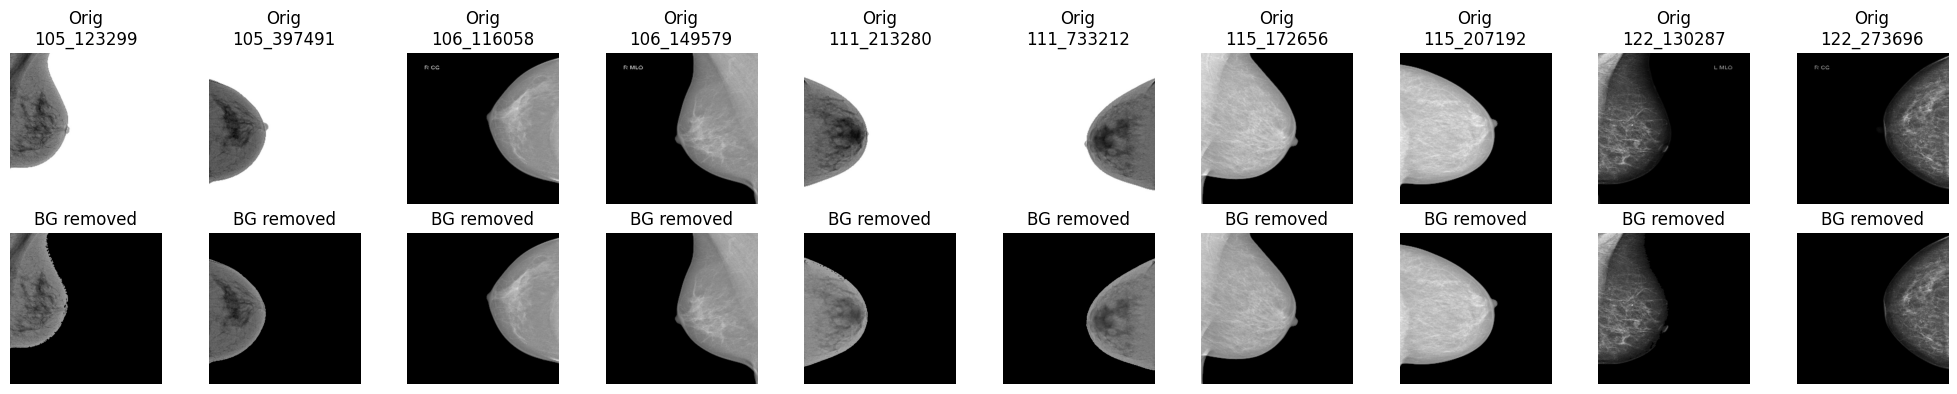

Class 1 examples:


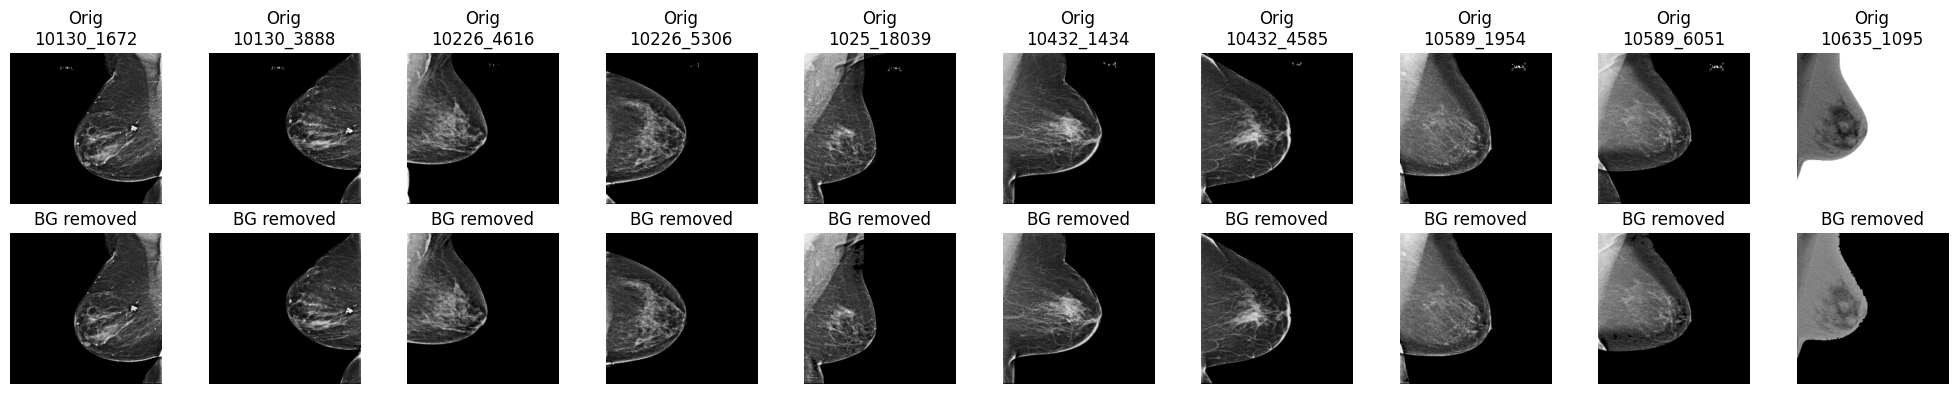

In [ ]:
# ==============================#
# Step 3: 20 examples (Original vs BG-removed)
# ==============================#
from PIL import Image

def show_many_examples(class_folder, n=10):
    files = sorted(list(Path(class_folder).glob("*.*")))[:n]
    if len(files) == 0:
        print(f"No images found in {class_folder}")
        return
    fig, axes = plt.subplots(2, len(files), figsize=(2*len(files), 4))
    for i, fp in enumerate(files):
        raw = Image.open(fp).convert("L")
        masked = bg_remove(raw)

        axes[0, i].imshow(raw, cmap="gray")
        axes[0, i].set_title(f"Orig\n{fp.stem[:10]}")
        axes[0, i].axis("off")

        axes[1, i].imshow(masked, cmap="gray")
        axes[1, i].set_title("BG removed")
        axes[1, i].axis("off")
    plt.tight_layout(); plt.show()

print("Class 0 examples:")
show_many_examples(train_dir/"0", n=10)

print("Class 1 examples:")
show_many_examples(train_dir/"1", n=10)


# Datasets & dataloaders (bound to current bg settings)

This stage prepares the mammogram data for efficient use in model training and evaluation. The ImageGolder utility is employed to automatically infer class labels from the directory structure, ensuring a consistent mapping between folders names and class indices. To maintain alignment with the preprocessing pipeline, the dataset are bound to the background removal and transform setting defined earlier, ensuring that all the images that enters the CNNs model are all standardized, artifact removed, resized, and normalized. A counting function is then used to verify the class distribution in all the splits, which shows the imbalance of the dataset. In this case, all the 3 sets contains similar number of cancer and non-cancer samples, the need of stratified sampling is not required.

For training stability, the data is loaded into small batches and shuffled into epoch to prevent the model from memorizing sample order. Validation and test loaders are kept deterministic to ensure reproducible evaluation. The use of pin_memory and num_worker optimizes the output and reduces I/O bottlenecks, making the pipeloine more efficient for GPU environments. Thus creating a robust and reproducible pipleline ensuring that subsequent models learn similar input from the preprocessed pipeline while having separate subsets of data.

In [ ]:
# ==============================#
# Step 4: Datasets & Dataloaders
# ==============================#
train_ds = datasets.ImageFolder(root=str(train_dir), transform=train_tfms)
valid_ds = datasets.ImageFolder(root=str(valid_dir), transform=eval_tfms)
test_ds  = datasets.ImageFolder(root=str(test_dir),  transform=eval_tfms)

print("Class-to-index:", train_ds.class_to_idx)

def count_targets(ds):
    counts = {c:0 for c in ds.class_to_idx.values()}
    for _, y in ds.samples:
        counts[y] += 1
    return counts

print("Train counts:", {CLASS_NAMES[k]: v for k, v in count_targets(train_ds).items()})
print("Valid counts:", {CLASS_NAMES[k]: v for k, v in count_targets(valid_ds).items()})
print("Test  counts:", {CLASS_NAMES[k]: v for k, v in count_targets(test_ds).items()})

BATCH_SIZE = 16
NUM_WORKERS = 2

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)


Class-to-index: {'0': 0, '1': 1}
Train counts: {'non-cancer': 1569, 'cancer': 803}
Valid counts: {'non-cancer': 448, 'cancer': 227}
Test  counts: {'non-cancer': 208, 'cancer': 128}


# Hypertuning Best Model Resnet50

[INFO] Saving all outputs to: /content/drive/MyDrive/colab_models/simple_run
Loading ResNet50 with ImageNet pretrained weights... (trial)
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 01 | train_loss=0.7168 train_acc=0.560 | val_loss=0.7880 val_acc=0.416 val_prec=0.359 val_rec=0.934 val_f1=0.518
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 02 | train_loss=0.6803 train_acc=0.591 | val_loss=0.6501 val_acc=0.627 val_prec=0.438 val_rec=0.392 val_f1=0.414
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 03 | train_loss=0.6649 train_acc=0.615 | val_loss=0.6682 val_acc=0.628 val_prec=0.443 val_rec=0.410 val_f1=0.426
  -> Early stopping triggered.
Loading ResNet50 with ImageNet pretrained weights... (tri

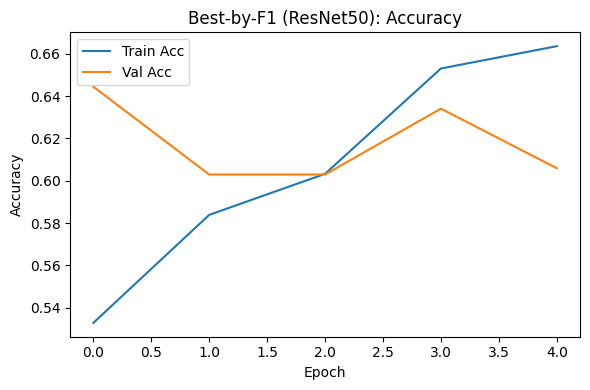

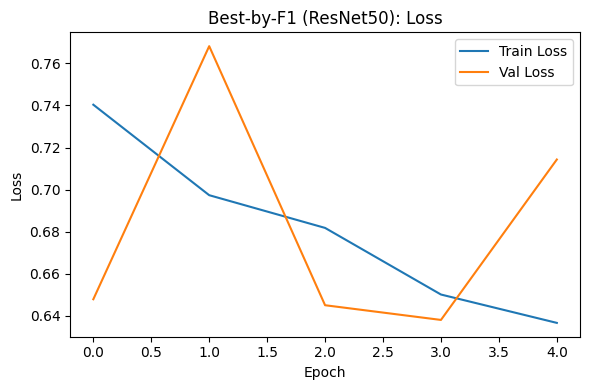

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_best_by_f1.csv


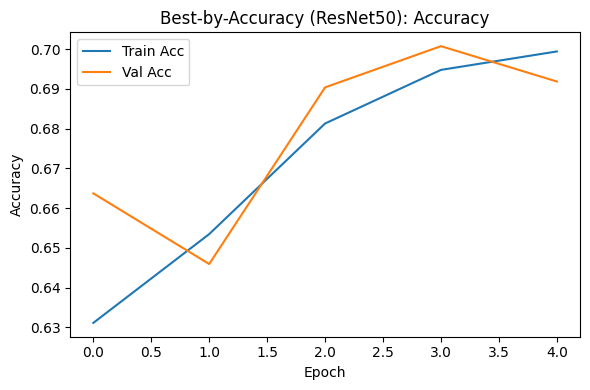

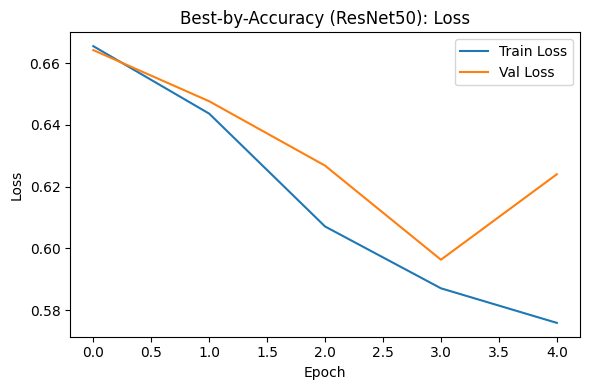

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_best_by_accuracy.csv


In [ ]:
# ==============================#
# Step 5.1: Hyperparameter tuning (mini-grid) + metrics
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt  # for curves
from pathlib import Path

# ---- Save directory (Drive) ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Saving all outputs to: {SAVE_DIR.resolve()}")

# ---- Training budget variables----
MAX_EPOCHS = 5   # maximum number of training epochs
PATIENCE   = 2   # stop early if no val F1 improvement

def build_model(dropout_p: float = 0.5) -> nn.Module:
    """Create a fresh ImageNet-pretrained ResNet50 with a binary head"""
    print("Loading ResNet50 with ImageNet pretrained weights... (trial)")
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    in_feats = m.fc.in_features
    m.fc = nn.Sequential(
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str = "freeze_block1"):
    """
    Freeze policy:
      - 'freeze_block1': freeze stem (conv1/bn1) + layer1, fine-tune the rest
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True
    if mode == "freeze_block1":
        to_freeze = []
        to_freeze += list(model.conv1.parameters())
        to_freeze += list(model.bn1.parameters())
        to_freeze += list(model.layer1.parameters())
        for p in to_freeze:
            p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

def train_one_epoch(model, loader, criterion, optimizer):
    """One full training epoch; returns average loss and accuracy."""
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_with_loss(model, loader, criterion):
    """Eval pass returning loss and classification metrics (accuracy/precision/recall/F1)."""
    model.eval()
    loss_sum, seen = 0.0, 0
    all_preds, all_targets = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        seen += xb.size(0)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_targets.append(yb.cpu())

    y_true = torch.cat(all_targets).numpy()
    y_pred = torch.cat(all_preds).numpy()
    avg_loss = loss_sum / max(1, seen)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return avg_loss, {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# --- class balancing ---
def get_class_weights():
    counts = count_targets(train_ds)
    total = sum(counts.values())
    weights = [total / counts[c] for c in range(len(counts))]
    return torch.tensor(weights, dtype=torch.float).to(DEVICE)

class_weights = get_class_weights()

def fit_and_eval(hparams):
    """
    Train on TRAIN set only; evaluate on VALID set; early-stop on val F1.
    Returns: model(best-epoch), best_val_metrics, history_dict (lists).
    """
    model = build_model(dropout_p=hparams["dropout"])
    freeze_strategy(model, hparams["freeze"])

    if hparams["class_weighting"]:
        criterion = nn.CrossEntropyLoss(weight=class_weights)
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=hparams["lr"],
        weight_decay=hparams["weight_decay"]
    )
    # Fixed scheduler: ReduceLROnPlateau on validation F1
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    # ---- track per-epoch metrics (incl. precision/recall/F1) ----
    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [],  "val_acc": [],
        "val_prec": [], "val_rec": [], "val_f1": []
    }

    best_state = copy.deepcopy(model.state_dict())
    best_val_f1 = -math.inf
    best_metrics = None
    epochs_no_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_metrics = evaluate_with_loss(model, valid_loader, criterion)
        val_f1 = val_metrics["f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_prec"].append(val_metrics["precision"])
        history["val_rec"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])

        print(f"[Trial {hparams}] Epoch {epoch:02d} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_metrics['accuracy']:.3f} "
              f"val_prec={val_metrics['precision']:.3f} val_rec={val_metrics['recall']:.3f} "
              f"val_f1={val_f1:.3f}")

        scheduler.step(val_f1)

        if val_f1 > best_val_f1:
            best_val_f1  = val_f1
            best_metrics = val_metrics
            best_state   = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print("  -> Early stopping triggered.")
                break

    # load best weights
    model.load_state_dict(best_state)
    return model, best_metrics, history

# ----- Grid search  -----
param_grid = [
    {"freeze": f, "lr": lr, "weight_decay": 1e-4, "dropout": d,
     "scheduler": "plateau", "class_weighting": cw}
    for f in ["freeze_block1", "train_all"]
    for lr in [1e-4, 3e-4]
    for d in [0.2, 0.4, 0.6]
    for cw in [True, False]
]

results = []
best_model_f1_state, best_f1_metrics, best_f1_hparams, best_f1_history = None, None, None, None
best_model_acc_state, best_acc_metrics, best_acc_hparams, best_acc_history = None, None, None, None

best_f1 = -1.0
best_acc = -1.0

tuning_start = time.time()
for hp in param_grid:
    t0 = time.time()
    model_t, val_metrics, hist = fit_and_eval(hp)
    elapsed = time.time() - t0
    row = {
        **hp,
        "val_acc": val_metrics["accuracy"], "val_prec": val_metrics["precision"],
        "val_rec": val_metrics["recall"], "val_f1": val_metrics["f1"],
        "time_s": elapsed
    }
    results.append(row)

    # Track best by F1
    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        best_model_f1_state = copy.deepcopy(model_t.state_dict())
        best_f1_metrics = val_metrics
        best_f1_hparams = hp
        best_f1_history = hist

    # Track best by Accuracy
    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        best_model_acc_state = copy.deepcopy(model_t.state_dict())
        best_acc_metrics = val_metrics
        best_acc_hparams = hp
        best_acc_history = hist

tuning_elapsed = time.time() - tuning_start

# Pretty print results sorted by F1 + save CSV
import pandas as pd
df = pd.DataFrame(results).sort_values(by="val_f1", ascending=False)
print("\n=== Validation metrics per trial (sorted by F1) ===")
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nTuning total wall time: {tuning_elapsed/60.0:.2f} min")

summary_csv = SAVE_DIR / "tuning_results.csv"
df.to_csv(summary_csv, index=False)
print(f"Wrote summary CSV: {summary_csv}")

# ---- Save best models (state_dict + metadata) ----
f1_model_path  = SAVE_DIR / "best_resnet50_by_f1.pth"
acc_model_path = SAVE_DIR / "best_resnet50_by_accuracy.pth"

torch.save(
    {"state_dict": best_model_f1_state, "hparams": best_f1_hparams, "metrics": best_f1_metrics},
    f1_model_path
)
torch.save(
    {"state_dict": best_model_acc_state, "hparams": best_acc_hparams, "metrics": best_acc_metrics},
    acc_model_path
)
print("\nSaved:")
print(f" - {f1_model_path}   {best_f1_hparams} {best_f1_metrics}")
print(f" - {acc_model_path}  {best_acc_hparams} {best_acc_metrics}")

# ---- Plot learning curves for the two winners ----
def plot_curves(history, title_prefix, save_prefix):
    # Accuracy curves
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title_prefix}: Accuracy")
    plt.legend(); plt.tight_layout()
    acc_path = SAVE_DIR / f"{save_prefix}_accuracy.png"
    plt.savefig(acc_path, dpi=150)
    plt.show()

    # Loss curves
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix}: Loss")
    plt.legend(); plt.tight_layout()
    loss_path = SAVE_DIR / f"{save_prefix}_loss.png"
    plt.savefig(loss_path, dpi=150)
    plt.show()

def save_history_csv(history, hparams, outfile):
    import pandas as pd
    epochs = list(range(1, len(history["train_loss"]) + 1))
    hist_df = pd.DataFrame({
        "epoch": epochs,
        "train_loss": history["train_loss"],
        "val_loss":   history["val_loss"],
        "train_acc":  history["train_acc"],
        "val_acc":    history["val_acc"],
        "val_prec":   history["val_prec"],
        "val_rec":    history["val_rec"],
        "val_f1":     history["val_f1"],
        "freeze":           [hparams["freeze"]]*len(epochs),
        "lr":               [hparams["lr"]]*len(epochs),
        "dropout":          [hparams["dropout"]]*len(epochs),
        "class_weighting":  [hparams["class_weighting"]]*len(epochs),
        "weight_decay":     [hparams["weight_decay"]]*len(epochs),
        "scheduler":        [hparams["scheduler"]]*len(epochs),
    })
    out_path = SAVE_DIR / outfile
    hist_df.to_csv(out_path, index=False)
    print(f"Wrote history CSV: {out_path}")

if best_f1_history is not None:
    plot_curves(best_f1_history, "Best-by-F1 (ResNet50)", "curves_best_by_f1")
    save_history_csv(best_f1_history, best_f1_hparams, "history_best_by_f1.csv")

if best_acc_history is not None:
    plot_curves(best_acc_history, "Best-by-Accuracy (ResNet50)", "curves_best_by_accuracy")
    save_history_csv(best_acc_history, best_acc_hparams, "history_best_by_accuracy.csv")


# Hypertuning Best Model DenseNet121

[INFO] Saving all outputs to: /content/drive/MyDrive/colab_models/simple_run
Loading DenseNet121 with ImageNet pretrained weights... (trial)
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 133MB/s]


[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 01 | train_loss=0.7057 train_acc=0.554 | val_loss=0.7004 val_acc=0.553 val_prec=0.388 val_rec=0.573 val_f1=0.463
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 02 | train_loss=0.6776 train_acc=0.608 | val_loss=0.6818 val_acc=0.594 val_prec=0.428 val_rec=0.617 val_f1=0.505
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 03 | train_loss=0.6298 train_acc=0.653 | val_loss=0.6231 val_acc=0.676 val_prec=0.524 val_rec=0.392 val_f1=0.448
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 04 | train_loss=0.6099 train_acc=0.667 | val_loss=0.6143 val_acc=0.665 val_prec=0

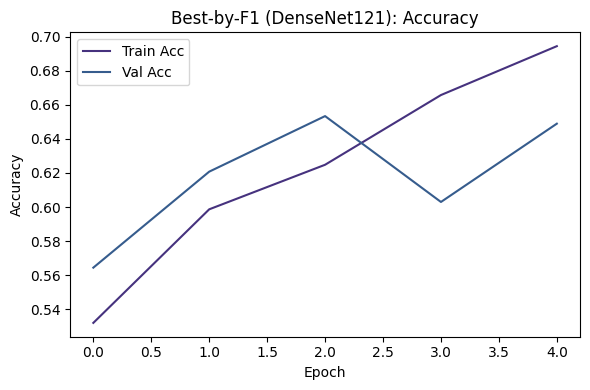

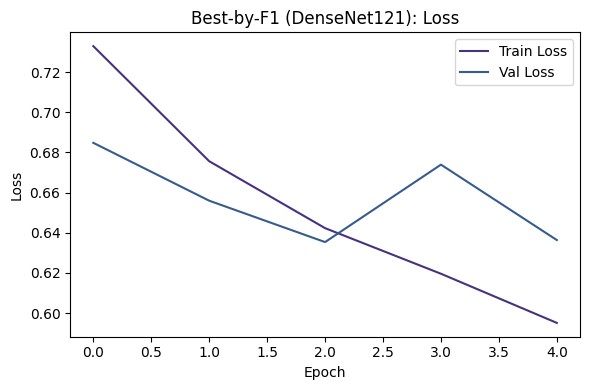

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_best_by_f1.csv


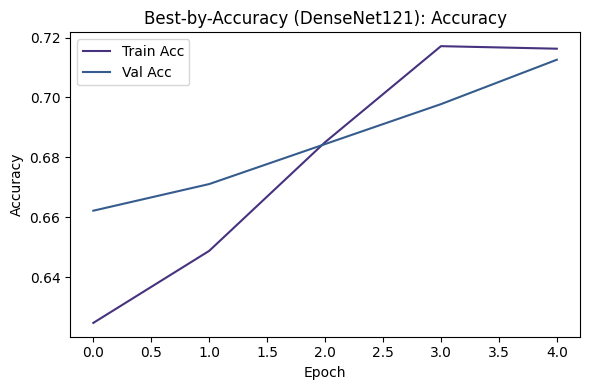

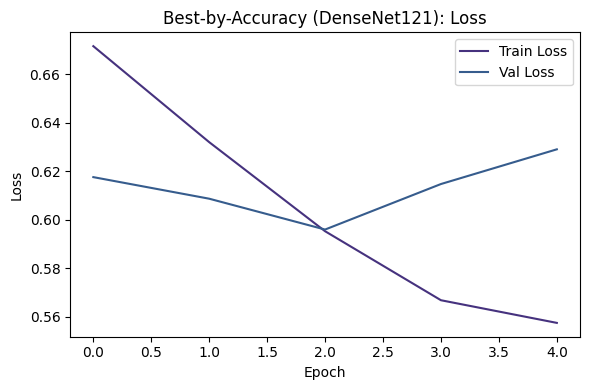

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_best_by_accuracy.csv


In [ ]:
# ==============================#
# Step 5.1: Hyperparameter tuning (mini-grid) + metrics
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt  # for curves
from pathlib import Path

# ---- Save directory (Drive) ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Saving all outputs to: {SAVE_DIR.resolve()}")

# ---- Training budget variables ----
MAX_EPOCHS = 5   # maximum number of training epochs
PATIENCE   = 2   # stop early if no val F1 improvement after this many epochs

def build_model(dropout_p: float = 0.5) -> nn.Module:
    """Create a fresh ImageNet-pretrained DenseNet121 with a binary head (for fair per-trial comparison)."""
    print("Loading DenseNet121 with ImageNet pretrained weights... (trial)")
    m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
    in_feats = m.classifier.in_features  # 1024 for DenseNet121
    # Replace classifier with Dropout + Linear(1024->2)
    m.classifier = nn.Sequential(
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def _set_requires_grad(module, flag: bool):
    for p in module.parameters():
        p.requires_grad = flag

def freeze_strategy(model: nn.Module, mode: str = "freeze_block1"):
    """
    Freeze policy for DenseNet121:
      - 'freeze_block1': freeze early stem + first dense block:
            features.conv0, norm0, relu0, pool0,
            features.denseblock1, features.transition1
        (fine-tune from denseblock2 onward)
      - 'train_all'    : unfreeze everything
    """
    # unfreeze all first
    for p in model.parameters():
        p.requires_grad = True

    if mode == "freeze_block1":
        feats = model.features
        to_freeze = [
            feats.conv0, feats.norm0, feats.relu0, feats.pool0,
            feats.denseblock1, feats.transition1
        ]
        for mod in to_freeze:
            _set_requires_grad(mod, False)
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

def train_one_epoch(model, loader, criterion, optimizer):
    """One full training epoch; returns average loss and accuracy."""
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_with_loss(model, loader, criterion):
    """Eval pass returning loss and classification metrics (accuracy/precision/recall/F1)."""
    model.eval()
    loss_sum, seen = 0.0, 0
    all_preds, all_targets = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        seen += xb.size(0)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_targets.append(yb.cpu())

    y_true = torch.cat(all_targets).numpy()
    y_pred = torch.cat(all_preds).numpy()
    avg_loss = loss_sum / max(1, seen)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return avg_loss, {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# --- class balancing ---
def get_class_weights():
    counts = count_targets(train_ds)
    total = sum(counts.values())
    weights = [total / counts[c] for c in range(len(counts))]
    return torch.tensor(weights, dtype=torch.float).to(DEVICE)

class_weights = get_class_weights()

def fit_and_eval(hparams):
    """
    Train on TRAIN set only; evaluate on VALID set; early-stop on val F1.
    Returns: model(best-epoch), best_val_metrics, history_dict (lists).
    """
    model = build_model(dropout_p=hparams["dropout"])
    freeze_strategy(model, hparams["freeze"])

    if hparams["class_weighting"]:
        criterion = nn.CrossEntropyLoss(weight=class_weights)
    else:
        criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=hparams["lr"],
        weight_decay=hparams["weight_decay"]
    )
    # Fixed scheduler: ReduceLROnPlateau on validation F1
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    # ---- track per-epoch metrics (incl. precision/recall/F1) ----
    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [],  "val_acc": [],
        "val_prec": [], "val_rec": [], "val_f1": []
    }

    best_state = copy.deepcopy(model.state_dict())
    best_val_f1 = -math.inf
    best_metrics = None
    epochs_no_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_metrics = evaluate_with_loss(model, valid_loader, criterion)
        val_f1 = val_metrics["f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_prec"].append(val_metrics["precision"])
        history["val_rec"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])

        print(f"[Trial {hparams}] Epoch {epoch:02d} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_metrics['accuracy']:.3f} "
              f"val_prec={val_metrics['precision']:.3f} val_rec={val_metrics['recall']:.3f} "
              f"val_f1={val_f1:.3f}")

        scheduler.step(val_f1)

        if val_f1 > best_val_f1:
            best_val_f1  = val_f1
            best_metrics = val_metrics
            best_state   = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print("  -> Early stopping triggered.")
                break

    # load best weights
    model.load_state_dict(best_state)
    return model, best_metrics, history

# ----- Reduced search space (still 24 trials) -----
param_grid = [
    {"freeze": f, "lr": lr, "weight_decay": 1e-4, "dropout": d,
     "scheduler": "plateau", "class_weighting": cw}
    for f in ["freeze_block1", "train_all"]
    for lr in [1e-4, 3e-4]
    for d in [0.2, 0.4, 0.6]
    for cw in [True, False]
]

results = []
best_model_f1_state, best_f1_metrics, best_f1_hparams, best_f1_history = None, None, None, None
best_model_acc_state, best_acc_metrics, best_acc_hparams, best_acc_history = None, None, None, None

best_f1 = -1.0
best_acc = -1.0

tuning_start = time.time()
for hp in param_grid:
    t0 = time.time()
    model_t, val_metrics, hist = fit_and_eval(hp)
    elapsed = time.time() - t0
    row = {
        **hp,
        "val_acc": val_metrics["accuracy"], "val_prec": val_metrics["precision"],
        "val_rec": val_metrics["recall"], "val_f1": val_metrics["f1"],
        "time_s": elapsed
    }
    results.append(row)

    # Track best by F1
    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        best_model_f1_state = copy.deepcopy(model_t.state_dict())
        best_f1_metrics = val_metrics
        best_f1_hparams = hp
        best_f1_history = hist

    # Track best by Accuracy
    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        best_model_acc_state = copy.deepcopy(model_t.state_dict())
        best_acc_metrics = val_metrics
        best_acc_hparams = hp
        best_acc_history = hist

tuning_elapsed = time.time() - tuning_start

# Pretty print results sorted by F1 + save CSV
import pandas as pd
df = pd.DataFrame(results).sort_values(by="val_f1", ascending=False)
print("\n=== Validation metrics per trial (sorted by F1) ===")
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nTuning total wall time: {tuning_elapsed/60.0:.2f} min")

summary_csv = SAVE_DIR / "tuning_results.csv"
df.to_csv(summary_csv, index=False)
print(f"Wrote summary CSV: {summary_csv}")

# ---- Save best models (state_dict + metadata) ----
f1_model_path  = SAVE_DIR / "best_densenet121_by_f1.pth"
acc_model_path = SAVE_DIR / "best_densenet121_by_accuracy.pth"

torch.save(
    {"state_dict": best_model_f1_state, "hparams": best_f1_hparams, "metrics": best_f1_metrics},
    f1_model_path
)
torch.save(
    {"state_dict": best_model_acc_state, "hparams": best_acc_hparams, "metrics": best_acc_metrics},
    acc_model_path
)
print("\nSaved:")
print(f" - {f1_model_path}   {best_f1_hparams} {best_f1_metrics}")
print(f" - {acc_model_path}  {best_acc_hparams} {best_acc_metrics}")

# ---- Plot learning curves for the two winners ----
def plot_curves(history, title_prefix, save_prefix):
    # Accuracy curves
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title_prefix}: Accuracy")
    plt.legend(); plt.tight_layout()
    acc_path = SAVE_DIR / f"{save_prefix}_accuracy.png"
    plt.savefig(acc_path, dpi=150)
    plt.show()

    # Loss curves
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix}: Loss")
    plt.legend(); plt.tight_layout()
    loss_path = SAVE_DIR / f"{save_prefix}_loss.png"
    plt.savefig(loss_path, dpi=150)
    plt.show()

def save_history_csv(history, hparams, outfile):
    import pandas as pd
    epochs = list(range(1, len(history["train_loss"]) + 1))
    hist_df = pd.DataFrame({
        "epoch": epochs,
        "train_loss": history["train_loss"],
        "val_loss":   history["val_loss"],
        "train_acc":  history["train_acc"],
        "val_acc":    history["val_acc"],
        "val_prec":   history["val_prec"],
        "val_rec":    history["val_rec"],
        "val_f1":     history["val_f1"],
        "freeze":           [hparams["freeze"]]*len(epochs),
        "lr":               [hparams["lr"]]*len(epochs),
        "dropout":          [hparams["dropout"]]*len(epochs),
        "class_weighting":  [hparams["class_weighting"]]*len(epochs),
        "weight_decay":     [hparams["weight_decay"]]*len(epochs),
        "scheduler":        [hparams["scheduler"]]*len(epochs),
    })
    out_path = SAVE_DIR / outfile
    hist_df.to_csv(out_path, index=False)
    print(f"Wrote history CSV: {out_path}")

if best_f1_history is not None:
    plot_curves(best_f1_history, "Best-by-F1 (DenseNet121)", "curves_best_by_f1")
    save_history_csv(best_f1_history, best_f1_hparams, "history_best_by_f1.csv")

if best_acc_history is not None:
    plot_curves(best_acc_history, "Best-by-Accuracy (DenseNet121)", "curves_best_by_accuracy")
    save_history_csv(best_acc_history, best_acc_hparams, "history_best_by_accuracy.csv")


# Hypertuning Best Model VGG16

[INFO] Saving all outputs to: /content/drive/MyDrive/colab_models/simple_run
Loading VGG16 with ImageNet pretrained weights... (trial)
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 180MB/s]


[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 01 | train_loss=0.7024 train_acc=0.536 | val_loss=0.6647 val_acc=0.545 val_prec=0.392 val_rec=0.639 val_f1=0.486
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 02 | train_loss=0.6883 train_acc=0.541 | val_loss=0.7511 val_acc=0.359 val_prec=0.340 val_rec=0.960 val_f1=0.502
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 03 | train_loss=0.6947 train_acc=0.538 | val_loss=0.7094 val_acc=0.336 val_prec=0.336 val_rec=1.000 val_f1=0.503
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 04 | train_loss=0.6953 train_acc=0.532 | val_loss=0.6911 val_acc=0.548 val_prec=0

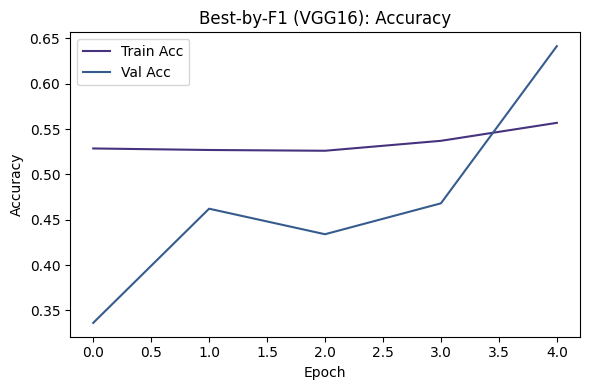

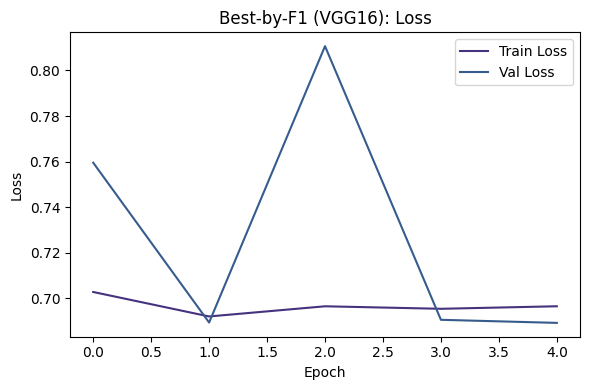

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_vgg16_best_by_f1.csv


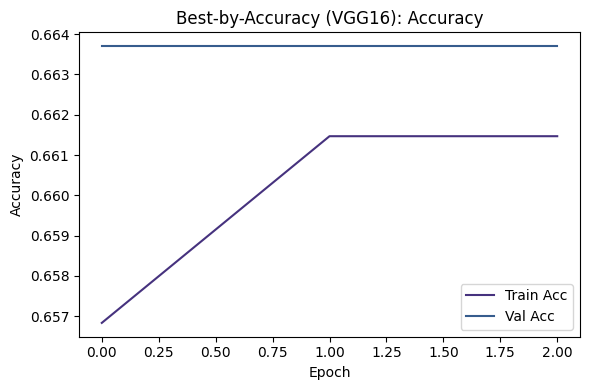

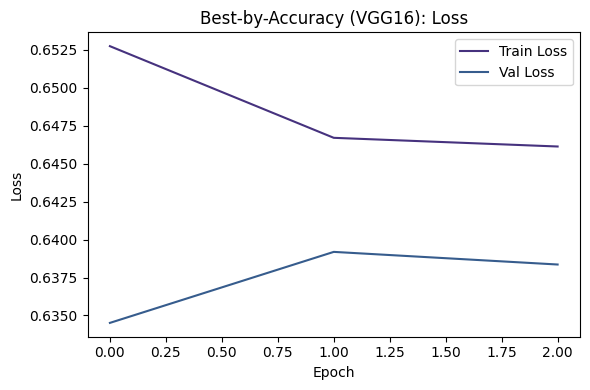

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_vgg16_best_by_accuracy.csv


In [ ]:
# ==============================#
# Step 5.1: Hyperparameter tuning (mini-grid) + metrics
# (VGG16 variant)
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt  # for curves
from pathlib import Path

# ---- Save directory (Drive) ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Saving all outputs to: {SAVE_DIR.resolve()}")

# ---- Training budget variables ----
MAX_EPOCHS = 5   # maximum number of training epochs
PATIENCE   = 2   # stop early if no val F1 improvement after this many epochs

def build_model(dropout_p: float = 0.5) -> nn.Module:
    """Create a fresh ImageNet-pretrained VGG16 with a binary head."""
    print("Loading VGG16 with ImageNet pretrained weights... (trial)")
    m = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

    # VGG16 classifier indices: [0]=FC(25088->4096), [2]=Dropout, [3]=FC(4096->4096),
    # [5]=Dropout, [6]=FC(4096->1000)
    in_feats = m.classifier[6].in_features  # 4096
    # adjust dropouts to our hparam
    m.classifier[2] = nn.Dropout(p=float(dropout_p))
    m.classifier[5] = nn.Dropout(p=float(dropout_p))
    # swap final layer to 2-way
    m.classifier[6] = nn.Linear(in_feats, 2)
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str = "freeze_block1"):
    """
    Freeze policy for VGG16:
      - 'freeze_block1': freeze early conv blocks (features[:10]) -> conv1_* + pool1 + conv2_* + pool2
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True

    if mode == "freeze_block1":
        # Freeze first two conv blocks
        for p in model.features[:10].parameters():
            p.requires_grad = False
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

def train_one_epoch(model, loader, criterion, optimizer):
    """One full training epoch; returns average loss and accuracy."""
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_with_loss(model, loader, criterion):
    """Eval pass returning loss and classification metrics (accuracy/precision/recall/F1)."""
    model.eval()
    loss_sum, seen = 0.0, 0
    all_preds, all_targets = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        seen += xb.size(0)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_targets.append(yb.cpu())

    y_true = torch.cat(all_targets).numpy()
    y_pred = torch.cat(all_preds).numpy()
    avg_loss = loss_sum / max(1, seen)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return avg_loss, {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# --- class balancing ---
def get_class_weights():
    counts = count_targets(train_ds)
    total = sum(counts.values())
    weights = [total / counts[c] for c in range(len(counts))]
    return torch.tensor(weights, dtype=torch.float).to(DEVICE)

class_weights = get_class_weights()

def fit_and_eval(hparams):
    """
    Train on TRAIN set only; evaluate on VALID set; early-stop on val F1.
    Returns: model(best-epoch), best_val_metrics, history_dict (lists).
    """
    model = build_model(dropout_p=hparams["dropout"])
    freeze_strategy(model, hparams["freeze"])

    criterion = nn.CrossEntropyLoss(weight=class_weights if hparams["class_weighting"] else None)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=hparams["lr"],
        weight_decay=hparams["weight_decay"]
    )
    # Fixed scheduler: ReduceLROnPlateau on validation F1
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    # ---- track per-epoch metrics (incl. precision/recall/F1) ----
    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [],  "val_acc": [],
        "val_prec": [], "val_rec": [], "val_f1": []
    }

    best_state = copy.deepcopy(model.state_dict())
    best_val_f1 = -math.inf
    best_metrics = None
    epochs_no_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_metrics = evaluate_with_loss(model, valid_loader, criterion)
        val_f1 = val_metrics["f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_prec"].append(val_metrics["precision"])
        history["val_rec"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])

        print(f"[Trial {hparams}] Epoch {epoch:02d} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_metrics['accuracy']:.3f} "
              f"val_prec={val_metrics['precision']:.3f} val_rec={val_metrics['recall']:.3f} "
              f"val_f1={val_f1:.3f}")

        scheduler.step(val_f1)

        if val_f1 > best_val_f1:
            best_val_f1  = val_f1
            best_metrics = val_metrics
            best_state   = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print("  -> Early stopping triggered.")
                break

    # load best weights
    model.load_state_dict(best_state)
    return model, best_metrics, history

# ----- Reduced search space (24 trials) -----
param_grid = [
    {"freeze": f, "lr": lr, "weight_decay": 1e-4, "dropout": d,
     "scheduler": "plateau", "class_weighting": cw}
    for f in ["freeze_block1", "train_all"]
    for lr in [1e-4, 3e-4]
    for d in [0.2, 0.4, 0.6]
    for cw in [True, False]
]

results = []
best_model_f1_state, best_f1_metrics, best_f1_hparams, best_f1_history = None, None, None, None
best_model_acc_state, best_acc_metrics, best_acc_hparams, best_acc_history = None, None, None, None

best_f1 = -1.0
best_acc = -1.0

tuning_start = time.time()
for hp in param_grid:
    t0 = time.time()
    model_t, val_metrics, hist = fit_and_eval(hp)
    elapsed = time.time() - t0
    row = {
        **hp,
        "val_acc": val_metrics["accuracy"], "val_prec": val_metrics["precision"],
        "val_rec": val_metrics["recall"], "val_f1": val_metrics["f1"],
        "time_s": elapsed
    }
    results.append(row)

    # Track best by F1
    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        best_model_f1_state = copy.deepcopy(model_t.state_dict())
        best_f1_metrics = val_metrics
        best_f1_hparams = hp
        best_f1_history = hist

    # Track best by Accuracy
    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        best_model_acc_state = copy.deepcopy(model_t.state_dict())
        best_acc_metrics = val_metrics
        best_acc_hparams = hp
        best_acc_history = hist

tuning_elapsed = time.time() - tuning_start

# Pretty print results sorted by F1 + save CSV
import pandas as pd
df = pd.DataFrame(results).sort_values(by="val_f1", ascending=False)
print("\n=== Validation metrics per trial (sorted by F1) ===")
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nTuning total wall time: {tuning_elapsed/60.0:.2f} min")

summary_csv = SAVE_DIR / "tuning_results_vgg16.csv"
df.to_csv(summary_csv, index=False)
print(f"Wrote summary CSV: {summary_csv}")

# ---- Save best models (state_dict + metadata) ----
f1_model_path  = SAVE_DIR / "best_vgg16_by_f1.pth"
acc_model_path = SAVE_DIR / "best_vgg16_by_accuracy.pth"

torch.save(
    {"state_dict": best_model_f1_state, "hparams": best_f1_hparams, "metrics": best_f1_metrics},
    f1_model_path
)
torch.save(
    {"state_dict": best_model_acc_state, "hparams": best_acc_hparams, "metrics": best_acc_metrics},
    acc_model_path
)
print("\nSaved:")
print(f" - {f1_model_path}   {best_f1_hparams} {best_f1_metrics}")
print(f" - {acc_model_path}  {best_acc_hparams} {best_acc_metrics}")

# ---- Plot learning curves for the two winners ----
def plot_curves(history, title_prefix, save_prefix):
    # Accuracy curves
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title_prefix}: Accuracy")
    plt.legend(); plt.tight_layout()
    acc_path = SAVE_DIR / f"{save_prefix}_accuracy.png"
    plt.savefig(acc_path, dpi=150)
    plt.show()

    # Loss curves
    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title_prefix}: Loss")
    plt.legend(); plt.tight_layout()
    loss_path = SAVE_DIR / f"{save_prefix}_loss.png"
    plt.savefig(loss_path, dpi=150)
    plt.show()

def save_history_csv(history, hparams, outfile):
    import pandas as pd
    epochs = list(range(1, len(history["train_loss"]) + 1))
    hist_df = pd.DataFrame({
        "epoch": epochs,
        "train_loss": history["train_loss"],
        "val_loss":   history["val_loss"],
        "train_acc":  history["train_acc"],
        "val_acc":    history["val_acc"],
        "val_prec":   history["val_prec"],
        "val_rec":    history["val_rec"],
        "val_f1":     history["val_f1"],
        "freeze":           [hparams["freeze"]]*len(epochs),
        "lr":               [hparams["lr"]]*len(epochs),
        "dropout":          [hparams["dropout"]]*len(epochs),
        "class_weighting":  [hparams["class_weighting"]]*len(epochs),
        "weight_decay":     [hparams["weight_decay"]]*len(epochs),
        "scheduler":        [hparams["scheduler"]]*len(epochs),
    })
    out_path = SAVE_DIR / outfile
    hist_df.to_csv(out_path, index=False)
    print(f"Wrote history CSV: {out_path}")

if best_f1_history is not None:
    plot_curves(best_f1_history, "Best-by-F1 (VGG16)", "vgg16_curves_best_by_f1")
    save_history_csv(best_f1_history, best_f1_hparams, "history_vgg16_best_by_f1.csv")

if best_acc_history is not None:
    plot_curves(best_acc_history, "Best-by-Accuracy (VGG16)", "vgg16_curves_best_by_accuracy")
    save_history_csv(best_acc_history, best_acc_hparams, "history_vgg16_best_by_accuracy.csv")


# Hypertuning Best Model ConvNext

[INFO] Saving all outputs to: /content/drive/MyDrive/colab_models/simple_run
Loading ConvNeXt-Small with ImageNet pretrained weights... (trial)
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 01 | train_loss=0.7087 train_acc=0.519 | val_loss=0.6953 val_acc=0.501 val_prec=0.381 val_rec=0.775 val_f1=0.511
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 02 | train_loss=0.6784 train_acc=0.573 | val_loss=0.6763 val_acc=0.547 val_prec=0.414 val_rec=0.833 val_f1=0.553
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 03 | train_loss=0.6526 train_acc=0.623 | val_loss=0.6025 val_acc=0.698 val_prec=0.658 val_rec=0.211 val_f1=0.320
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout'

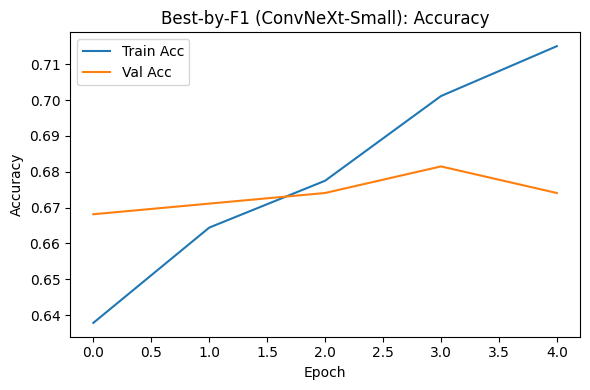

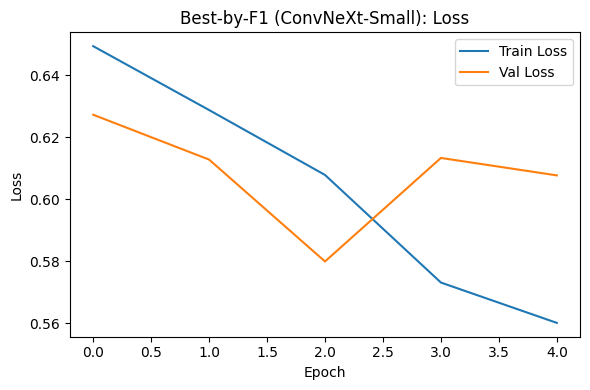

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_convnext_small_best_by_f1.csv


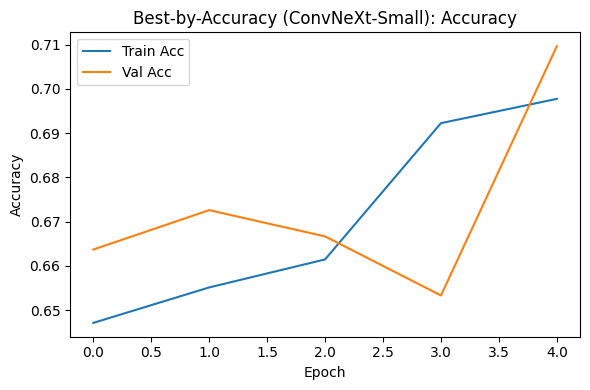

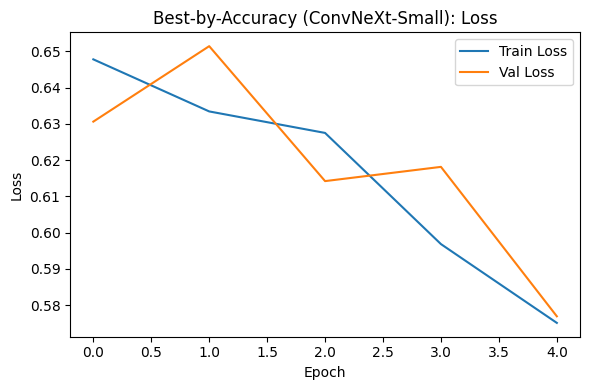

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_convnext_small_best_by_accuracy.csv


In [ ]:
# ==============================#
# Step 5.1: Hyperparameter tuning (mini-grid) + metrics
# (ConvNeXt-Small variant)
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt  # for curves
from pathlib import Path

# ---- Save directory (Drive) ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Saving all outputs to: {SAVE_DIR.resolve()}")

# ---- Training budget variables  ----
MAX_EPOCHS = 5   # maximum number of training epochs
PATIENCE   = 2   # stop early if no val F1 improvement after this many epochs

def build_model(dropout_p: float = 0.5) -> nn.Module:
    """Create a fresh ImageNet-pretrained ConvNeXt-Small with a binary head."""
    print("Loading ConvNeXt-Small with ImageNet pretrained weights... (trial)")
    m = models.convnext_small(weights=models.ConvNeXt_Small_Weights.IMAGENET1K_V1)

    # Classifier: [LayerNorm2d, Flatten(1), Linear]
    ln = m.classifier[0]
    fl = m.classifier[1]
    fc = m.classifier[2]
    in_feats = fc.in_features

    # Keep LN+Flatten, insert Dropout, replace Linear -> 2 classes
    m.classifier = nn.Sequential(
        ln,
        fl,
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str = "freeze_block1"):
    """
    Freeze policy for ConvNeXt-Small:
      - 'freeze_block1': freeze stem + very early stages in model.features (first ~2 submodules)
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True

    if mode == "freeze_block1":
        try:
            for idx, mod in enumerate(model.features):
                if idx <= 2:
                    for p in mod.parameters():
                        p.requires_grad = False
                else:
                    break
        except Exception:
            frozen = 0
            for _, mod in model.features.named_children():
                for p in mod.parameters():
                    p.requires_grad = False
                frozen += 1
                if frozen >= 2:
                    break
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

def train_one_epoch(model, loader, criterion, optimizer):
    """One full training epoch; returns average loss and accuracy."""
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_with_loss(model, loader, criterion):
    """Eval pass returning loss and classification metrics (accuracy/precision/recall/F1)."""
    model.eval()
    loss_sum, seen = 0.0, 0
    all_preds, all_targets = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        seen += xb.size(0)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_targets.append(yb.cpu())

    y_true = torch.cat(all_targets).numpy()
    y_pred = torch.cat(all_preds).numpy()
    avg_loss = loss_sum / max(1, seen)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return avg_loss, {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# --- class balancing ---
def get_class_weights():
    counts = count_targets(train_ds)
    total = sum(counts.values())
    weights = [total / counts[c] for c in range(len(counts))]
    return torch.tensor(weights, dtype=torch.float).to(DEVICE)

class_weights = get_class_weights()

def fit_and_eval(hparams):
    """
    Train on TRAIN set only; evaluate on VALID set; early-stop on val F1.
    Returns: model(best-epoch), best_val_metrics, history_dict (lists).
    """
    model = build_model(dropout_p=hparams["dropout"])
    freeze_strategy(model, hparams["freeze"])

    criterion = nn.CrossEntropyLoss(weight=class_weights if hparams["class_weighting"] else None)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=hparams["lr"],
        weight_decay=hparams["weight_decay"]
    )
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [],
               "val_prec": [], "val_rec": [], "val_f1": []}

    best_state = copy.deepcopy(model.state_dict())
    best_val_f1 = -math.inf
    best_metrics = None
    epochs_no_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_metrics = evaluate_with_loss(model, valid_loader, criterion)
        val_f1 = val_metrics["f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_prec"].append(val_metrics["precision"])
        history["val_rec"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])

        print(f"[Trial {hparams}] Epoch {epoch:02d} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_metrics['accuracy']:.3f} "
              f"val_prec={val_metrics['precision']:.3f} val_rec={val_metrics['recall']:.3f} "
              f"val_f1={val_f1:.3f}")

        scheduler.step(val_f1)

        if val_f1 > best_val_f1:
            best_val_f1  = val_f1
            best_metrics = val_metrics
            best_state   = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print("  -> Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    return model, best_metrics, history

# ----- Reduced search space (24 trials) -----
param_grid = [
    {"freeze": f, "lr": lr, "weight_decay": 1e-4, "dropout": d,
     "scheduler": "plateau", "class_weighting": cw}
    for f in ["freeze_block1", "train_all"]
    for lr in [1e-4, 3e-4]
    for d in [0.2, 0.4, 0.6]
    for cw in [True, False]
]

results = []
best_model_f1_state, best_f1_metrics, best_f1_hparams, best_f1_history = None, None, None, None
best_model_acc_state, best_acc_metrics, best_acc_hparams, best_acc_history = None, None, None, None

best_f1 = -1.0
best_acc = -1.0

tuning_start = time.time()
for hp in param_grid:
    t0 = time.time()
    model_t, val_metrics, hist = fit_and_eval(hp)
    elapsed = time.time() - t0
    row = {
        **hp,
        "val_acc": val_metrics["accuracy"], "val_prec": val_metrics["precision"],
        "val_rec": val_metrics["recall"], "val_f1": val_metrics["f1"],
        "time_s": elapsed
    }
    results.append(row)

    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        best_model_f1_state = copy.deepcopy(model_t.state_dict())
        best_f1_metrics = val_metrics
        best_f1_hparams = hp
        best_f1_history = hist

    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        best_model_acc_state = copy.deepcopy(model_t.state_dict())
        best_acc_metrics = val_metrics
        best_acc_hparams = hp
        best_acc_history = hist

tuning_elapsed = time.time() - tuning_start

# Pretty print results sorted by F1 + save CSV
import pandas as pd
df = pd.DataFrame(results).sort_values(by="val_f1", ascending=False)
print("\n=== Validation metrics per trial (sorted by F1) ===")
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nTuning total wall time: {tuning_elapsed/60.0:.2f} min")

summary_csv = SAVE_DIR / "tuning_results_convnext_small.csv"
df.to_csv(summary_csv, index=False)
print(f"Wrote summary CSV: {summary_csv}")

# ---- Save best models (state_dict + metadata) ----
f1_model_path  = SAVE_DIR / "best_convnext_small_by_f1.pth"
acc_model_path = SAVE_DIR / "best_convnext_small_by_accuracy.pth"

torch.save(
    {"state_dict": best_model_f1_state, "hparams": best_f1_hparams, "metrics": best_f1_metrics},
    f1_model_path
)
torch.save(
    {"state_dict": best_model_acc_state, "hparams": best_acc_hparams, "metrics": best_acc_metrics},
    acc_model_path
)
print("\nSaved:")
print(f" - {f1_model_path}   {best_f1_hparams} {best_f1_metrics}")
print(f" - {acc_model_path}  {best_acc_hparams} {best_acc_metrics}")

# ---- Plot learning curves for the two winners ----
def plot_curves(history, title_prefix, save_prefix):
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy")
    plt.title(f"{title_prefix}: Accuracy")
    plt.legend(); plt.tight_layout()
    acc_path = SAVE_DIR / f"{save_prefix}_accuracy.png"
    plt.savefig(acc_path, dpi=150)
    plt.show()

    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title(f"{title_prefix}: Loss")
    plt.legend(); plt.tight_layout()
    loss_path = SAVE_DIR / f"{save_prefix}_loss.png"
    plt.savefig(loss_path, dpi=150)
    plt.show()

def save_history_csv(history, hparams, outfile):
    import pandas as pd
    epochs = list(range(1, len(history["train_loss"]) + 1))
    hist_df = pd.DataFrame({
        "epoch": epochs,
        "train_loss": history["train_loss"],
        "val_loss":   history["val_loss"],
        "train_acc":  history["train_acc"],
        "val_acc":    history["val_acc"],
        "val_prec":   history["val_prec"],
        "val_rec":    history["val_rec"],
        "val_f1":     history["val_f1"],
        "freeze":           [hparams["freeze"]]*len(epochs),
        "lr":               [hparams["lr"]]*len(epochs),
        "dropout":          [hparams["dropout"]]*len(epochs),
        "class_weighting":  [hparams["class_weighting"]]*len(epochs),
        "weight_decay":     [hparams["weight_decay"]]*len(epochs),
        "scheduler":        [hparams["scheduler"]]*len(epochs),
    })
    out_path = SAVE_DIR / outfile
    hist_df.to_csv(out_path, index=False)
    print(f"Wrote history CSV: {out_path}")

if best_f1_history is not None:
    plot_curves(best_f1_history, "Best-by-F1 (ConvNeXt-Small)", "convnext_small_curves_best_by_f1")
    save_history_csv(best_f1_history, best_f1_hparams, "history_convnext_small_best_by_f1.csv")

if best_acc_history is not None:
    plot_curves(best_acc_history, "Best-by-Accuracy (ConvNeXt-Small)", "convnext_small_curves_best_by_accuracy")
    save_history_csv(best_acc_history, best_acc_hparams, "history_convnext_small_best_by_accuracy.csv")


# Hypertuning Best Model EfficientNet

[INFO] Saving all outputs to: /content/drive/MyDrive/colab_models/simple_run
Loading EfficientNet-V2-S with ImageNet pretrained weights... (trial)
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 213MB/s]


[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 01 | train_loss=0.6931 train_acc=0.549 | val_loss=0.6578 val_acc=0.593 val_prec=0.396 val_rec=0.401 val_f1=0.398
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 02 | train_loss=0.6595 train_acc=0.610 | val_loss=0.6780 val_acc=0.601 val_prec=0.424 val_rec=0.515 val_f1=0.465
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 03 | train_loss=0.6485 train_acc=0.624 | val_loss=0.6172 val_acc=0.653 val_prec=0.483 val_rec=0.427 val_f1=0.453
[Trial {'freeze': 'freeze_block1', 'lr': 0.0001, 'weight_decay': 0.0001, 'dropout': 0.2, 'scheduler': 'plateau', 'class_weighting': True}] Epoch 04 | train_loss=0.6063 train_acc=0.683 | val_loss=0.6652 val_acc=0.624 val_prec=0

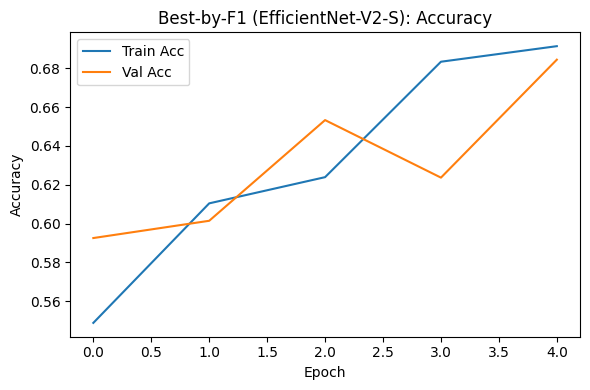

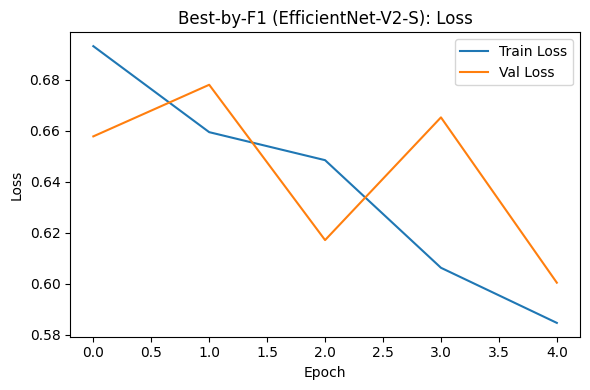

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_efficientnet_v2_s_best_by_f1.csv


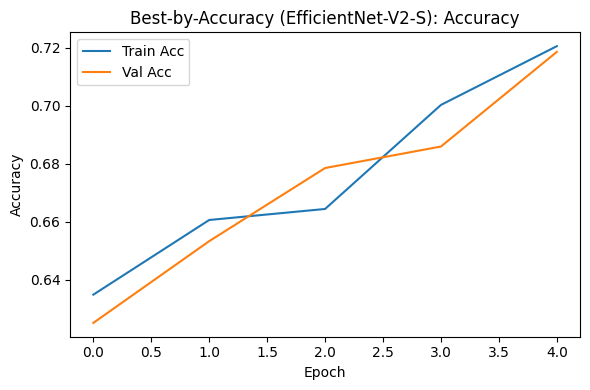

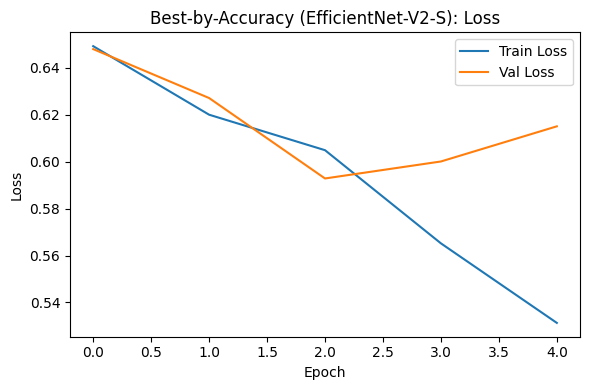

Wrote history CSV: /content/drive/MyDrive/colab_models/simple_run/history_efficientnet_v2_s_best_by_accuracy.csv


In [ ]:
# ==============================#
# Step 5.1: Hyperparameter tuning (mini-grid) + metrics
# (EfficientNet-V2-S variant)
# ==============================#
import copy, math, time
import torch
import torch.nn as nn
from torchvision import models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt  # for curves
from pathlib import Path

# ---- Save directory (Drive) ----
SAVE_DIR = Path('/content/drive/MyDrive/colab_models/simple_run')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
print(f"[INFO] Saving all outputs to: {SAVE_DIR.resolve()}")

# ---- Training budget variables  ----
MAX_EPOCHS = 5   # maximum number of training epochs
PATIENCE   = 2   # stop early if no val F1 improvement after this many epochs

def build_model(dropout_p: float = 0.5) -> nn.Module:
    """Create a fresh ImageNet-pretrained EfficientNet-V2-S with a binary head."""
    print("Loading EfficientNet-V2-S with ImageNet pretrained weights... (trial)")
    m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)

    # Torchvision EfficientNet-V2-S head: classifier = [Dropout, Linear]
    in_feats = m.classifier[1].in_features
    m.classifier = nn.Sequential(
        nn.Dropout(p=float(dropout_p)),
        nn.Linear(in_feats, 2)
    )
    return m.to(DEVICE)

def freeze_strategy(model: nn.Module, mode: str = "freeze_block1"):
    """
    Freeze policy for EfficientNet-V2-S:
      - 'freeze_block1': freeze the earliest stages in model.features (first ~2 modules)
      - 'train_all'    : unfreeze everything
    """
    for p in model.parameters():
        p.requires_grad = True

    if mode == "freeze_block1":
        frozen = 0
        for _, mod in model.features.named_children():
            for p in mod.parameters():
                p.requires_grad = False
            frozen += 1
            if frozen >= 2:  # freeze first two blocks
                break
    elif mode == "train_all":
        pass
    else:
        raise ValueError(f"Unknown freeze mode: {mode}")

def train_one_epoch(model, loader, criterion, optimizer):
    """One full training epoch; returns average loss and accuracy."""
    model.train()
    running_loss, running_correct, seen = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        running_loss   += loss.item() * xb.size(0)
        preds = logits.argmax(dim=1)
        running_correct += (preds == yb).sum().item()
        seen += xb.size(0)

    avg_loss = running_loss / max(1, seen)
    avg_acc  = running_correct / max(1, seen)
    return avg_loss, avg_acc

@torch.no_grad()
def evaluate_with_loss(model, loader, criterion):
    """Eval pass returning loss and classification metrics (accuracy/precision/recall/F1)."""
    model.eval()
    loss_sum, seen = 0.0, 0
    all_preds, all_targets = [], []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        loss = criterion(logits, yb)
        loss_sum += loss.item() * xb.size(0)
        seen += xb.size(0)
        preds = logits.argmax(dim=1)
        all_preds.append(preds.cpu())
        all_targets.append(yb.cpu())

    y_true = torch.cat(all_targets).numpy()
    y_pred = torch.cat(all_preds).numpy()
    avg_loss = loss_sum / max(1, seen)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", pos_label=1, zero_division=0
    )
    return avg_loss, {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}

# --- class balancing ---
def get_class_weights():
    counts = count_targets(train_ds)
    total = sum(counts.values())
    weights = [total / counts[c] for c in range(len(counts))]
    return torch.tensor(weights, dtype=torch.float).to(DEVICE)

class_weights = get_class_weights()

def fit_and_eval(hparams):
    """
    Train on TRAIN set only; evaluate on VALID set; early-stop on val F1.
    Returns: model(best-epoch), best_val_metrics, history_dict (lists).
    """
    model = build_model(dropout_p=hparams["dropout"])
    freeze_strategy(model, hparams["freeze"])

    criterion = nn.CrossEntropyLoss(weight=class_weights if hparams["class_weighting"] else None)

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=hparams["lr"],
        weight_decay=hparams["weight_decay"]
    )
    # Scheduler: ReduceLROnPlateau on validation F1
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [],
               "val_prec": [], "val_rec": [], "val_f1": []}

    best_state = copy.deepcopy(model.state_dict())
    best_val_f1 = -math.inf
    best_metrics = None
    epochs_no_improve = 0

    for epoch in range(1, MAX_EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        val_loss, val_metrics = evaluate_with_loss(model, valid_loader, criterion)
        val_f1 = val_metrics["f1"]

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_prec"].append(val_metrics["precision"])
        history["val_rec"].append(val_metrics["recall"])
        history["val_f1"].append(val_metrics["f1"])

        print(f"[Trial {hparams}] Epoch {epoch:02d} | "
              f"train_loss={train_loss:.4f} train_acc={train_acc:.3f} | "
              f"val_loss={val_loss:.4f} val_acc={val_metrics['accuracy']:.3f} "
              f"val_prec={val_metrics['precision']:.3f} val_rec={val_metrics['recall']:.3f} "
              f"val_f1={val_f1:.3f}")

        scheduler.step(val_f1)

        if val_f1 > best_val_f1:
            best_val_f1  = val_f1
            best_metrics = val_metrics
            best_state   = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                print("  -> Early stopping triggered.")
                break

    model.load_state_dict(best_state)
    return model, best_metrics, history

# ----- Search space (24 trials) -----
param_grid = [
    {"freeze": f, "lr": lr, "weight_decay": 1e-4, "dropout": d,
     "scheduler": "plateau", "class_weighting": cw}
    for f in ["freeze_block1", "train_all"]
    for lr in [1e-4, 3e-4]
    for d in [0.2, 0.4, 0.6]
    for cw in [True, False]
]

results = []
best_model_f1_state, best_f1_metrics, best_f1_hparams, best_f1_history = None, None, None, None
best_model_acc_state, best_acc_metrics, best_acc_hparams, best_acc_history = None, None, None, None

best_f1 = -1.0
best_acc = -1.0

tuning_start = time.time()
for hp in param_grid:
    t0 = time.time()
    model_t, val_metrics, hist = fit_and_eval(hp)
    elapsed = time.time() - t0
    row = {
        **hp,
        "val_acc": val_metrics["accuracy"], "val_prec": val_metrics["precision"],
        "val_rec": val_metrics["recall"], "val_f1": val_metrics["f1"],
        "time_s": elapsed
    }
    results.append(row)

    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]
        best_model_f1_state = copy.deepcopy(model_t.state_dict())
        best_f1_metrics = val_metrics
        best_f1_hparams = hp
        best_f1_history = hist

    if val_metrics["accuracy"] > best_acc:
        best_acc = val_metrics["accuracy"]
        best_model_acc_state = copy.deepcopy(model_t.state_dict())
        best_acc_metrics = val_metrics
        best_acc_hparams = hp
        best_acc_history = hist

tuning_elapsed = time.time() - tuning_start

# Pretty print results sorted by F1 + save CSV
import pandas as pd
df = pd.DataFrame(results).sort_values(by="val_f1", ascending=False)
print("\n=== Validation metrics per trial (sorted by F1) ===")
print(df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nTuning total wall time: {tuning_elapsed/60.0:.2f} min")

summary_csv = SAVE_DIR / "tuning_results_efficientnet_v2_s.csv"
df.to_csv(summary_csv, index=False)
print(f"Wrote summary CSV: {summary_csv}")

# ---- Save best models (state_dict + metadata) ----
f1_model_path  = SAVE_DIR / "best_efficientnet_v2_s_by_f1.pth"
acc_model_path = SAVE_DIR / "best_efficientnet_v2_s_by_accuracy.pth"

torch.save(
    {"state_dict": best_model_f1_state, "hparams": best_f1_hparams, "metrics": best_f1_metrics},
    f1_model_path
)
torch.save(
    {"state_dict": best_model_acc_state, "hparams": best_acc_hparams, "metrics": best_acc_metrics},
    acc_model_path
)
print("\nSaved:")
print(f" - {f1_model_path}   {best_f1_hparams} {best_f1_metrics}")
print(f" - {acc_model_path}  {best_acc_hparams} {best_acc_metrics}")

# ---- Plot learning curves for the two winners ----
def plot_curves(history, title_prefix, save_prefix):
    plt.figure(figsize=(6,4))
    plt.plot(history["train_acc"], label="Train Acc")
    plt.plot(history["val_acc"], label="Val Acc")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy")
    plt.title(f"{title_prefix}: Accuracy")
    plt.legend(); plt.tight_layout()
    acc_path = SAVE_DIR / f"{save_prefix}_accuracy.png"
    plt.savefig(acc_path, dpi=150)
    plt.show()

    plt.figure(figsize=(6,4))
    plt.plot(history["train_loss"], label="Train Loss")
    plt.plot(history["val_loss"], label="Val Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title(f"{title_prefix}: Loss")
    plt.legend(); plt.tight_layout()
    loss_path = SAVE_DIR / f"{save_prefix}_loss.png"
    plt.savefig(loss_path, dpi=150)
    plt.show()

def save_history_csv(history, hparams, outfile):
    import pandas as pd
    epochs = list(range(1, len(history["train_loss"]) + 1))
    hist_df = pd.DataFrame({
        "epoch": epochs,
        "train_loss": history["train_loss"],
        "val_loss":   history["val_loss"],
        "train_acc":  history["train_acc"],
        "val_acc":    history["val_acc"],
        "val_prec":   history["val_prec"],
        "val_rec":    history["val_rec"],
        "val_f1":     history["val_f1"],
        "freeze":           [hparams["freeze"]]*len(epochs),
        "lr":               [hparams["lr"]]*len(epochs),
        "dropout":          [hparams["dropout"]]*len(epochs),
        "class_weighting":  [hparams["class_weighting"]]*len(epochs),
        "weight_decay":     [hparams["weight_decay"]]*len(epochs),
        "scheduler":        [hparams["scheduler"]]*len(epochs),
    })
    out_path = SAVE_DIR / outfile
    hist_df.to_csv(out_path, index=False)
    print(f"Wrote history CSV: {out_path}")

if best_f1_history is not None:
    plot_curves(best_f1_history, "Best-by-F1 (EfficientNet-V2-S)", "efficientnet_v2_s_curves_best_by_f1")
    save_history_csv(best_f1_history, best_f1_hparams, "history_efficientnet_v2_s_best_by_f1.csv")

if best_acc_history is not None:
    plot_curves(best_acc_history, "Best-by-Accuracy (EfficientNet-V2-S)", "efficientnet_v2_s_curves_best_by_accuracy")
    save_history_csv(best_acc_history, best_acc_hparams, "history_efficientnet_v2_s_best_by_accuracy.csv")
